In [3]:
import sympy as sp
sp.init_printing()

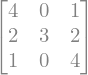

In [4]:
x = sp.symbols('x')
A = sp.Matrix([[4, 0, 1], [2,3,2], [1,0,4]])
A

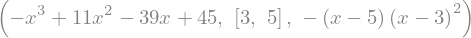

In [20]:
p = (A - x*sp.eye(3)).det()
p, sp.solve(p,x), sp.factor(p, x)



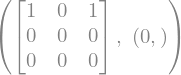

In [10]:
(A - 3*sp.eye(3)).rref()

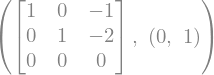

In [12]:
(A - 5*sp.eye(3)).rref()

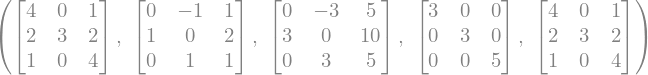

In [29]:
V = sp.Matrix([[0, -1, 1], [1, 0, 2], [0,1,1]])
D = V.inv()*A*V
A, V, A*V, V.inv()*A*V, V*D*V.inv() 

In [30]:
A**10 == V*D**10*V.inv()

True

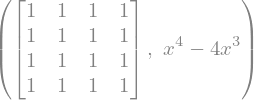

In [33]:
B = sp.Matrix([[1,1,1,1], [1,1,1,1], [1,1,1,1], [1,1,1,1]])
B, (B - x*sp.eye(4)).det()

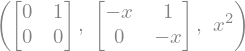

In [35]:
B = sp.Matrix([[0,1], [0,0]])
B, B - x*sp.eye(2), (B - x*sp.eye(2)).det()

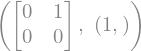

In [37]:
(B - 0*sp.eye(2)).rref()

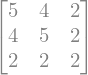

In [40]:
A = sp.Matrix([[5,4,2], [4,5,2], [2,2,2]])
A

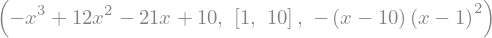

In [47]:
p = (A - x*sp.eye(3)).det()
p, sp.solve(p,x), p.factor(x)

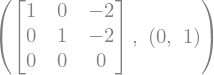

In [46]:
(A - 10*sp.eye(3)).rref()

In [5]:
import sympy as sp
sp.init_printing()
x = sp.symbols('x')

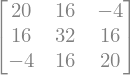

In [15]:
A = sp.Matrix([[20, 16, -4], [16, 32, 16], [-4, 16, 20]])
A

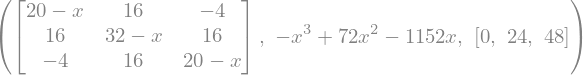

In [17]:
A - x*sp.eye(3), (A - x*sp.eye(3)).det(), sp.solve((A - x*sp.eye(3)).det(), x) 

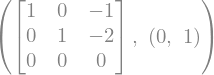

In [20]:
((A - (48)*sp.eye(3))).rref()

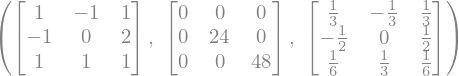

In [23]:
V = sp.Matrix([[1,-1,1], [-1,0,2], [1,1,1]])
V, V.inv()*A*V, V.inv()

# Valores y vectores propios. Diagonalización

En el [Cuaderno13](Cuaderno13.ipynb) vimos que aplicar una transformación $k$ veces equivale a calcular la potencia $A^k$ de su matriz, y que la sucesión de Fibonacci se obtiene de las potencias de $\begin{pmatrix}1&1\\1&0\end{pmatrix}$. Pero multiplicar matrices no revela **cómo** crece la sucesión. Para verlo hay que buscar las direcciones en las que la matriz actúa de la forma más simple posible: estirando, sin girar.

El plan del cuaderno es:

1. **Valores y vectores propios**: qué son y qué significan geométricamente.
2. **Cómo se calculan**: el polinomio característico y los espacios propios.
3. **Diagonalización**: cuándo se puede escribir $A=PDP^{-1}$ y por qué eso simplifica las potencias.
4. **Fibonacci**: diagonalizamos su matriz, paso a paso, y extraemos la fórmula cerrada
$$F_n=\frac{\varphi^n-\psi^n}{\sqrt5}.$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import display

AZUL, NARANJA, AGUAMARINA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_SUAVE, REJILLA = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA_SUAVE,
    "axes.titlecolor": TINTA,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "xtick.color": TINTA_SUAVE,
    "ytick.color": TINTA_SUAVE,
    "legend.frameon": False,
})

## 1. La idea: direcciones que la matriz no gira

Una matriz suele cambiar tanto la longitud como la dirección de un vector. Tomemos
$$A=\begin{pmatrix}2&1\\1&2\end{pmatrix}.$$
- Con $u=(1,0)$ se obtiene $Au=(2,1)$, que apunta en **otra dirección**.
- Con $v=(1,1)$ se obtiene $Av=(3,3)=3v$: **la misma dirección**, tres veces más largo.
- Con $w=(1,-1)$ se obtiene $Aw=(1,-1)=1\cdot w$: el vector no cambia.

Sobre las rectas generadas por $v$ y por $w$, la matriz se comporta como si fuera un simple número.

### 1.1 Definición

**Definición.** Sea $A$ una matriz $n\times n$. Un escalar $\lambda$ es un **valor propio** de $A$ si existe un vector $v\neq\mathbf 0$ tal que
$$\boxed{Av=\lambda v}.$$
Ese $v$ es un **vector propio** asociado a $\lambda$. Es decir, $v$ se transforma en un múltiplo de sí mismo.

**Observaciones.**
- Se exige $v\neq\mathbf 0$, porque $A\mathbf 0=\lambda\mathbf 0$ se cumple para todo $\lambda$ y no aportaría información.
- En cambio, $\lambda=0$ **sí** puede ser valor propio: significa que $Av=\mathbf 0$ para algún $v\ne\mathbf 0$.
- Si $v$ es vector propio, también lo es $cv$ con $c\neq0$, porque $A(cv)=cAv=\lambda(cv)$. Lo que importa es la **dirección**, no la longitud.

En el ejemplo, $A$ tiene los valores propios $\lambda_1=3$ y $\lambda_2=1$, con vectores propios $v$ y $w$.

### 1.2 La imagen geométrica

La figura aplica $A$ al círculo unitario, que se convierte en una elipse. Los ejes de la elipse están sobre las dos rectas propias.

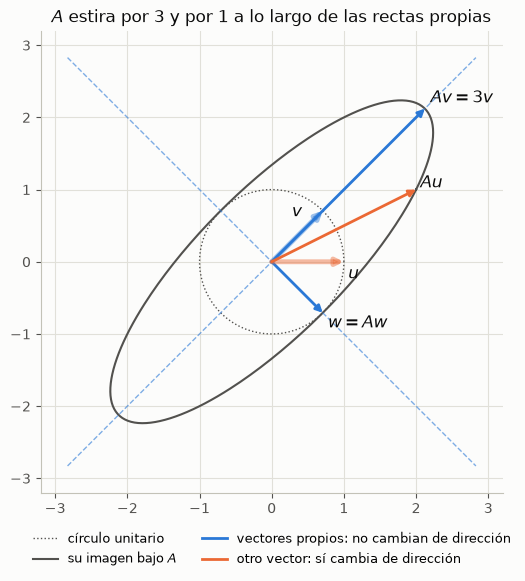

In [2]:
A = np.array([[2, 1], [1, 2]])
t = np.linspace(0, 2 * np.pi, 300)
circulo = np.vstack([np.cos(t), np.sin(t)])
elipse = A @ circulo

r = 1 / np.sqrt(2)
v, w, u = np.array([r, r]), np.array([r, -r]), np.array([1.0, 0.0])


def flecha(ax, destino, color, ancho=2.0, alfa=1.0):
    ax.annotate("", xy=destino, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=ancho, alpha=alfa, shrinkA=0, shrinkB=0))


fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(*circulo, color=TINTA_SUAVE, lw=1, linestyle=":", label="círculo unitario")
ax.plot(*elipse, color=TINTA_SUAVE, lw=1.5, label="su imagen bajo $A$")
for d in (v, w):
    ax.plot([-4 * d[0], 4 * d[0]], [-4 * d[1], 4 * d[1]], color=AZUL, lw=1, linestyle="--", alpha=0.6)

flecha(ax, A @ v, AZUL)
flecha(ax, v, AZUL, ancho=3.5, alfa=0.45)
flecha(ax, w, AZUL)
flecha(ax, A @ u, NARANJA)
flecha(ax, u, NARANJA, ancho=3.5, alfa=0.45)

ax.plot([], [], color=AZUL, lw=2, label="vectores propios: no cambian de dirección")
ax.plot([], [], color=NARANJA, lw=2, label="otro vector: sí cambia de dirección")

ax.text(0.28, 0.62, "$v$", color=TINTA, fontsize=12)
ax.text(2.20, 2.20, "$Av=3v$", color=TINTA, fontsize=12)
ax.text(0.78, -0.92, "$w=Aw$", color=TINTA, fontsize=12)
ax.text(1.06, -0.24, "$u$", color=TINTA, fontsize=12)
ax.text(2.06, 1.02, "$Au$", color=TINTA, fontsize=12)

ax.set_aspect("equal")
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(-3.2, 3.2)
ax.set_title("$A$ estira por 3 y por 1 a lo largo de las rectas propias")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=9)
plt.show()

### 1.3 Cuatro ejemplos en el plano

| Transformación | Matriz | Valores propios | Vectores propios | Lectura geométrica |
|---|---|---|---|---|
| Reflexión sobre el eje $x$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | $1,\ -1$ | $e_1,\ e_2$ | El eje $x$ queda fijo y el eje $y$ se invierte |
| Proyección sobre el eje $x$ | $\begin{pmatrix}1&0\\0&0\end{pmatrix}$ | $1,\ 0$ | $e_1,\ e_2$ | El eje $x$ queda fijo y el eje $y$ se aplasta en $\mathbf 0$ |
| Rotación de $90^\circ$ | $\begin{pmatrix}0&-1\\1&0\end{pmatrix}$ | ninguno real | ninguno real | Toda dirección gira |
| Cizalla | $\begin{pmatrix}1&1\\0&1\end{pmatrix}$ | $1$ (doble) | solo $e_1$ | Únicamente el eje $x$ conserva su dirección |

Los dos últimos casos anticipan que no toda matriz tiene "suficientes" direcciones propias. Volveremos a ellos en 3.3.

## 2. Cómo calcular valores y vectores propios

### 2.1 El polinomio característico

Reescribimos la definición:
$$Av=\lambda v\iff Av-\lambda v=\mathbf 0\iff (A-\lambda I)\,v=\mathbf 0 .$$
Buscamos soluciones **no triviales** de este sistema homogéneo, y existen exactamente cuando $A-\lambda I$ no es invertible:
$$\lambda\ \text{es valor propio de } A\iff \boxed{\det(A-\lambda I)=0}.$$
La expresión $p(\lambda)=\det(A-\lambda I)$ es un polinomio de grado $n$ en $\lambda$, llamado **polinomio característico**. Por eso $A$ tiene a lo sumo $n$ valores propios distintos.

Una vez hallado $\lambda$, sus vectores propios (junto con $\mathbf 0$) forman el **espacio propio**
$$E_\lambda=\operatorname{Nul}(A-\lambda I),$$
que es un subespacio de $\mathbb{R}^n$.

**Procedimiento.**
1. Calcular $\det(A-\lambda I)$ y hallar sus raíces.
2. Para cada raíz $\lambda$, resolver $(A-\lambda I)v=\mathbf 0$ por reducción y obtener una base de $E_\lambda$.

**Caso $2\times2$.** Para $A=\begin{pmatrix}a&b\\c&d\end{pmatrix}$,
$$\det(A-\lambda I)=(a-\lambda)(d-\lambda)-bc=\lambda^2-\underbrace{(a+d)}_{\operatorname{tr}A}\lambda+\det A .$$

### 2.2 Ejemplo $2\times2$

Sea $A=\begin{pmatrix}4&1\\2&3\end{pmatrix}$. Aquí $\operatorname{tr}A=7$ y $\det A=10$, de modo que
$$p(\lambda)=\lambda^2-7\lambda+10=(\lambda-5)(\lambda-2)\quad\Longrightarrow\quad\lambda_1=5,\ \ \lambda_2=2.$$

**Para $\lambda_1=5$:**
$$A-5I=\begin{pmatrix}-1&1\\2&-2\end{pmatrix}\xrightarrow{F_2+2F_1}\begin{pmatrix}-1&1\\0&0\end{pmatrix}\ \Rightarrow\ x_1=x_2\ \Rightarrow\ E_5=\operatorname{gen}\left\{\begin{pmatrix}1\\1\end{pmatrix}\right\}.$$

**Para $\lambda_2=2$:**
$$A-2I=\begin{pmatrix}2&1\\2&1\end{pmatrix}\xrightarrow{F_2-F_1}\begin{pmatrix}2&1\\0&0\end{pmatrix}\ \Rightarrow\ x_2=-2x_1\ \Rightarrow\ E_2=\operatorname{gen}\left\{\begin{pmatrix}1\\-2\end{pmatrix}\right\}.$$

**Comprobación.** $A(1,1)^T=(5,5)^T=5(1,1)^T$ ✓ y $A(1,-2)^T=(2,-4)^T=2(1,-2)^T$ ✓.

> **Control útil.** Las filas de $A-\lambda I$ deben ser dependientes. Si al reducir no aparece una fila de ceros, el valor de $\lambda$ está mal calculado.

### 2.3 Ejemplo $3\times3$ con un valor propio repetido

Sea $B=\begin{pmatrix}4&0&1\\2&3&2\\1&0&4\end{pmatrix}$. Desarrollando el determinante por la segunda columna:
$$\det(B-\lambda I)=(3-\lambda)\begin{vmatrix}4-\lambda&1\\1&4-\lambda\end{vmatrix}=(3-\lambda)\big[(4-\lambda)^2-1\big]=(3-\lambda)(3-\lambda)(5-\lambda).$$
Los valores propios son $\lambda=3$ (raíz doble) y $\lambda=5$ (raíz simple).

**Para $\lambda=3$:**
$$B-3I=\begin{pmatrix}1&0&1\\2&0&2\\1&0&1\end{pmatrix}\to\begin{pmatrix}1&0&1\\0&0&0\\0&0&0\end{pmatrix}\ \Rightarrow\ x_1=-x_3,\ \ x_2,x_3\text{ libres},\qquad E_3=\operatorname{gen}\left\{\begin{pmatrix}0\\1\\0\end{pmatrix},\begin{pmatrix}-1\\0\\1\end{pmatrix}\right\}.$$

**Para $\lambda=5$:**
$$B-5I=\begin{pmatrix}-1&0&1\\2&-2&2\\1&0&-1\end{pmatrix}\to\begin{pmatrix}1&0&-1\\0&1&-2\\0&0&0\end{pmatrix}\ \Rightarrow\ x_1=x_3,\ \ x_2=2x_3,\qquad E_5=\operatorname{gen}\left\{\begin{pmatrix}1\\2\\1\end{pmatrix}\right\}.$$

El valor $\lambda=3$ es raíz doble y su espacio propio tiene dimensión 2. Esto no siempre ocurre, como veremos en 3.3.

### 2.4 Propiedades

Para una matriz $A$ de tamaño $n\times n$, con valores propios $\lambda_1,\dots,\lambda_n$ contados con multiplicidad (posiblemente complejos):

- $\lambda_1+\dots+\lambda_n=\operatorname{tr}A$ y $\lambda_1\cdots\lambda_n=\det A$. En el ejemplo $B$: $3+3+5=11=\operatorname{tr}B$ y $3\cdot3\cdot5=45=\det B$.
- $A$ es invertible $\iff$ $0$ **no** es valor propio.
- Si $A$ es triangular, sus valores propios son las entradas de la diagonal.
- **Potencias.** Si $Av=\lambda v$, entonces $A^kv=\lambda^kv$, porque
$$A^2v=A(Av)=A(\lambda v)=\lambda Av=\lambda^2v,$$
y así sucesivamente. Esta propiedad es la clave de todo lo que sigue.

### 2.5 En Python

SymPy calcula de forma exacta, aunque puede escalar los vectores de otra manera: para $\lambda=2$ da $(-\tfrac12,1)$, que es múltiplo de nuestro $(1,-2)$. NumPy calcula con decimales y devuelve vectores propios de **longitud 1**, por lo que también pueden verse distintos de los calculados a mano aunque generen la misma recta.

In [3]:
lam = sp.symbols("lambda")
A = sp.Matrix([[4, 1], [2, 3]])
B = sp.Matrix([[4, 0, 1], [2, 3, 2], [1, 0, 4]])

print("Polinomio característico de A y de B:")
display(sp.factor(A.charpoly(lam).as_expr()), sp.factor(B.charpoly(lam).as_expr()))

# Cada elemento es (valor propio, multiplicidad, base del espacio propio)
print("eigenvects de A:")
display(A.eigenvects())
print("eigenvects de B:")
display(B.eigenvects())

valores, vectores = np.linalg.eig(np.array([[4.0, 1.0], [2.0, 3.0]]))
# Según la versión, NumPy devuelve complejos con parte imaginaria 0; real_if_close los pasa a reales
valores, vectores = np.real_if_close(valores), np.real_if_close(vectores)
print("NumPy, valores propios de A:", valores)
print("NumPy, vectores propios de A (en las columnas, con longitud 1):")
print(vectores)

Polinomio característico de A y de B:


(lambda - 5)*(lambda - 2)

(lambda - 5)*(lambda - 3)**2

eigenvects de A:


[(2,
  1,
  [Matrix([
   [-1/2],
   [   1]])]),
 (5,
  1,
  [Matrix([
   [1],
   [1]])])]

eigenvects de B:


[(3,
  2,
  [Matrix([
   [0],
   [1],
   [0]]),
   Matrix([
   [-1],
   [ 0],
   [ 1]])]),
 (5,
  1,
  [Matrix([
   [1],
   [2],
   [1]])])]

NumPy, valores propios de A: [5. 2.]
NumPy, vectores propios de A (en las columnas, con longitud 1):
[[ 0.70710678 -0.4472136 ]
 [ 0.70710678  0.89442719]]


## 3. Diagonalización

### 3.1 Definición y teorema central

**Definición.** Una matriz $A$ de tamaño $n\times n$ es **diagonalizable** si existen una matriz invertible $P$ y una matriz diagonal $D$ tales que
$$\boxed{A=PDP^{-1}}.$$

**Teorema.** $A$ es diagonalizable $\iff$ $A$ tiene $n$ vectores propios linealmente independientes. En ese caso, las columnas de $P$ son esos vectores propios y la diagonal de $D$ contiene los valores propios **en el mismo orden**.

*Prueba.* Escribamos $P=[\,v_1\ \cdots\ v_n\,]$ y $D=\operatorname{diag}(\lambda_1,\dots,\lambda_n)$. Multiplicando por columnas,
$$AP=[\,Av_1\ \cdots\ Av_n\,],\qquad PD=[\,\lambda_1v_1\ \cdots\ \lambda_nv_n\,].$$
Por tanto, $AP=PD$ equivale a $Av_i=\lambda_iv_i$ para cada $i$. Además, $P$ es invertible exactamente cuando sus columnas son linealmente independientes (lo que también garantiza $v_i\ne\mathbf 0$). Finalmente, si $P$ es invertible, $AP=PD$ equivale a $A=PDP^{-1}$. $\blacksquare$

### 3.2 Procedimiento

1. Hallar los valores propios: raíces de $\det(A-\lambda I)=0$.
2. Hallar una base de cada espacio propio $E_\lambda=\operatorname{Nul}(A-\lambda I)$.
3. Si en total se obtienen $n$ vectores, formar $P$ con ellos como columnas. Si son menos de $n$, $A$ **no** es diagonalizable.
4. Formar $D$ con los valores propios en el mismo orden que los vectores de $P$.
5. Comprobar con $AP=PD$, que no requiere calcular la inversa.

**Ejemplo.** Con el ejemplo de 2.2:
$$P=\begin{pmatrix}1&1\\1&-2\end{pmatrix},\qquad D=\begin{pmatrix}5&0\\0&2\end{pmatrix},\qquad AP=\begin{pmatrix}5&2\\5&-4\end{pmatrix}=PD.\ ✓$$

La matriz $P$ no es única: se pueden reescalar sus columnas o cambiar su orden, siempre que $D$ se reordene igual.

### 3.3 ¿Cuándo se puede diagonalizar?

**Teorema.** Vectores propios asociados a valores propios **distintos** son linealmente independientes.

*Prueba para dos vectores.* Sean $Av_1=\lambda_1v_1$, $Av_2=\lambda_2v_2$ con $\lambda_1\ne\lambda_2$, y supongamos $c_1v_1+c_2v_2=\mathbf 0$. Aplicando $A$ se obtiene $c_1\lambda_1v_1+c_2\lambda_2v_2=\mathbf 0$. Restando $\lambda_2$ veces la primera ecuación:
$$c_1(\lambda_1-\lambda_2)v_1=\mathbf 0\ \Rightarrow\ c_1=0,$$
y entonces $c_2v_2=\mathbf 0$ implica $c_2=0$. El caso de $k$ vectores se obtiene por inducción con la misma idea. $\blacksquare$

**Corolario.** Si $A$ tiene $n$ valores propios **distintos**, entonces es diagonalizable. Esta condición es suficiente, pero no necesaria: la matriz $B$ de 2.3 tiene una raíz doble y sí es diagonalizable.

**Criterio general.** Para cada valor propio se definen dos multiplicidades:

- la **algebraica**, $m_a(\lambda)$: cuántas veces es raíz del polinomio característico;
- la **geométrica**, $m_g(\lambda)=\dim E_\lambda$: cuántos vectores propios independientes aporta.

Siempre se cumple $1\le m_g(\lambda)\le m_a(\lambda)$. Y $A$ es diagonalizable (sobre $\mathbb{R}$) exactamente cuando todas las raíces son reales y $m_g(\lambda)=m_a(\lambda)$ para cada una.

**Dos maneras de fallar:**

- **Faltan vectores propios.** $C=\begin{pmatrix}3&1\\0&3\end{pmatrix}$ tiene $\lambda=3$ doble, pero $C-3I=\begin{pmatrix}0&1\\0&0\end{pmatrix}$ obliga a $x_2=0$, así que $E_3=\operatorname{gen}\{e_1\}$ y $m_g=1<2=m_a$. Otra forma de verlo: si fuera diagonalizable, se tendría $C=P(3I)P^{-1}=3I$, lo cual es falso.
- **Raíces no reales.** La rotación $R=\begin{pmatrix}0&-1\\1&0\end{pmatrix}$ tiene $p(\lambda)=\lambda^2+1$, con raíces $\pm i$. No es diagonalizable sobre $\mathbb{R}$, aunque sí sobre $\mathbb{C}$.

### 3.4 Interpretación: un cambio de base

La diagonalización es un **cambio de coordenadas** en el sentido del [Cuaderno10](Cuaderno10.ipynb). Si $\mathcal B=\{v_1,\dots,v_n\}$ es la base de vectores propios, entonces $P=P_{\mathcal E\leftarrow\mathcal B}$ y $P^{-1}=P_{\mathcal B\leftarrow\mathcal E}$. Leyendo $Ax=PDP^{-1}x$ de derecha a izquierda:

$$\underbrace{x}_{\text{coordenadas canónicas}}\ \xrightarrow{\ P^{-1}\ }\ \underbrace{[x]_{\mathcal B}}_{\text{coordenadas propias}}\ \xrightarrow{\ D\ }\ \underbrace{D[x]_{\mathcal B}}_{\text{cada una se escala}}\ \xrightarrow{\ P\ }\ \underbrace{Ax}_{\text{de vuelta a las canónicas}}$$

Así, $D$ es la **misma transformación** $x\mapsto Ax$, vista en la base $\mathcal B$. En esa base cada coordenada se multiplica por su valor propio, sin mezclarse con las demás.

### 3.5 La gran ventaja: las potencias

Los factores $P^{-1}P$ del medio se cancelan:
$$A^2=PDP^{-1}PDP^{-1}=PD^2P^{-1},\qquad\text{y en general}\qquad\boxed{A^k=PD^kP^{-1}}.$$
Y una potencia de una matriz diagonal es inmediata:
$$D^k=\operatorname{diag}(\lambda_1^k,\dots,\lambda_n^k).$$

**Ejemplo.** Para $A=\begin{pmatrix}4&1\\2&3\end{pmatrix}$, con $P^{-1}=\frac13\begin{pmatrix}2&1\\1&-1\end{pmatrix}$:
$$A^k=\begin{pmatrix}1&1\\1&-2\end{pmatrix}\begin{pmatrix}5^k&0\\0&2^k\end{pmatrix}\frac13\begin{pmatrix}2&1\\1&-1\end{pmatrix}=\frac13\begin{pmatrix}2\cdot5^k+2^k&5^k-2^k\\2\cdot5^k-2\cdot2^k&5^k+2\cdot2^k\end{pmatrix}.$$
Con $k=2$ resulta $\frac13\begin{pmatrix}54&21\\42&33\end{pmatrix}=\begin{pmatrix}18&7\\14&11\end{pmatrix}$, que coincide con $A^2$ calculada directamente. ✓

Obtuvimos una **fórmula válida para todo $k$**, que además muestra el crecimiento: para $k$ grande domina $5^k$, el valor propio de mayor valor absoluto. Exactamente esto es lo que haremos con Fibonacci.

### 3.6 Verificación con SymPy

`diagonalize()` devuelve $P$ y $D$. Sus columnas pueden tener otra escala o aparecer en otro orden respecto a las calculadas a mano; ambas respuestas son válidas.

In [4]:
# Las matrices elegidas a mano
P_A = sp.Matrix([[1, 1], [1, -2]])
D_A = sp.diag(5, 2)
P_B = sp.Matrix([[0, -1, 1], [1, 0, 2], [0, 1, 1]])
D_B = sp.diag(3, 3, 5)

print("¿A P = P D para A?", A * P_A == P_A * D_A)
print("¿B P = P D para B?", B * P_B == P_B * D_B)
print("¿A = P D P^(-1) para B?", B == P_B * D_B * P_B.inv())

# La fórmula de A^k de la sección 3.5
k = sp.symbols("k", integer=True, positive=True)
A_k = P_A * sp.diag(5**k, 2**k) * P_A.inv()
print("A^k =")
display(sp.simplify(A_k))
print("¿La fórmula coincide con A^k directa para k = 1, ..., 10?",
      all(A_k.subs(k, j) == A**j for j in range(1, 11)))

print("Lo que devuelve diagonalize() para B:")
display(B.diagonalize())

C = sp.Matrix([[3, 1], [0, 3]])
R = sp.Matrix([[0, -1], [1, 0]])
print("¿C es diagonalizable?", C.is_diagonalizable())
print("¿R es diagonalizable sobre R?", R.is_diagonalizable(reals_only=True))
print("¿R es diagonalizable sobre C?", R.is_diagonalizable())

¿A P = P D para A? True
¿B P = P D para B? True
¿A = P D P^(-1) para B? True
A^k =


Matrix([
[   2**k/3 + 2*5**k/3,  -2**k/3 + 5**k/3],
[-2*2**k/3 + 2*5**k/3, 2*2**k/3 + 5**k/3]])

¿La fórmula coincide con A^k directa para k = 1, ..., 10? True
Lo que devuelve diagonalize() para B:


(Matrix([
 [0, -1, 1],
 [1,  0, 2],
 [0,  1, 1]]),
 Matrix([
 [3, 0, 0],
 [0, 3, 0],
 [0, 0, 5]]))

¿C es diagonalizable? False
¿R es diagonalizable sobre R? False
¿R es diagonalizable sobre C? True


## 4. Fibonacci: de la matriz a la fórmula cerrada

Recordemos del [Cuaderno13](Cuaderno13.ipynb) que, con $F_0=0$, $F_1=1$ y $F_{n+1}=F_n+F_{n-1}$,
$$x_n=\begin{pmatrix}F_{n+1}\\F_n\end{pmatrix}=A^nx_0,\qquad A=\begin{pmatrix}1&1\\1&0\end{pmatrix},\qquad x_0=\begin{pmatrix}1\\0\end{pmatrix},$$
y que para $n\ge1$
$$A^n=\begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}.$$

**Objetivo:** calcular $A^n$ de **otra manera**, con $A^n=PD^nP^{-1}$, y comparar las entradas. Seguimos el procedimiento de 3.2.

### Paso 1. Valores propios

$$\det(A-\lambda I)=\begin{vmatrix}1-\lambda&1\\1&-\lambda\end{vmatrix}=(1-\lambda)(-\lambda)-1=\lambda^2-\lambda-1 .$$
Con la fórmula cuadrática, las raíces son
$$\boxed{\varphi=\frac{1+\sqrt5}{2}\approx1.618,\qquad\psi=\frac{1-\sqrt5}{2}\approx-0.618.}$$
El número $\varphi$ es la **razón áurea**. Usaremos estas relaciones, todas inmediatas:
$$\varphi+\psi=1,\qquad\varphi\psi=-1,\qquad\varphi-\psi=\sqrt5,\qquad\varphi^2=\varphi+1,\qquad\psi^2=\psi+1 .$$
Las dos primeras son la traza y el determinante de $A$ (2.4). Las dos últimas dicen que $\varphi$ y $\psi$ son raíces de $\lambda^2-\lambda-1$.

**Observación.** La ecuación $\lambda^2=\lambda+1$ tiene la misma forma que $F_{n+1}=F_n+F_{n-1}$: la recurrencia ya contiene el polinomio característico.

### Paso 2. Vectores propios

Para $\lambda=\varphi$ resolvemos $(A-\varphi I)v=\mathbf 0$:
$$A-\varphi I=\begin{pmatrix}1-\varphi&1\\1&-\varphi\end{pmatrix}.$$
La segunda fila da $x_1-\varphi x_2=0$, es decir, $x_1=\varphi x_2$. Con $x_2=1$:
$$v=\begin{pmatrix}\varphi\\1\end{pmatrix}.$$
La primera fila no agrega nada, porque $(1-\varphi)\varphi+1=\varphi-\varphi^2+1=0$. El cálculo para $\psi$ es idéntico:
$$w=\begin{pmatrix}\psi\\1\end{pmatrix}.$$

**Comprobación directa** con $\varphi^2=\varphi+1$:
$$Av=\begin{pmatrix}\varphi+1\\\varphi\end{pmatrix}=\begin{pmatrix}\varphi^2\\\varphi\end{pmatrix}=\varphi\begin{pmatrix}\varphi\\1\end{pmatrix}=\varphi v.\ ✓\qquad\text{Igualmente, }Aw=\psi w.\ ✓$$

### Paso 3. Las matrices $P$ y $D$

Como $\varphi\ne\psi$, hay dos valores propios distintos y $A$ es diagonalizable (3.3):
$$P=\begin{pmatrix}\varphi&\psi\\1&1\end{pmatrix},\qquad D=\begin{pmatrix}\varphi&0\\0&\psi\end{pmatrix}.$$

### Paso 4. La inversa de $P$

Como $\det P=\varphi-\psi=\sqrt5$, la fórmula de la inversa $2\times2$ da
$$P^{-1}=\frac1{\sqrt5}\begin{pmatrix}1&-\psi\\-1&\varphi\end{pmatrix}.$$

**Comprobación de $A=PDP^{-1}$.** Primero, $PD=\begin{pmatrix}\varphi^2&\psi^2\\\varphi&\psi\end{pmatrix}$. Después,
$$PDP^{-1}=\frac1{\sqrt5}\begin{pmatrix}\varphi^2-\psi^2&\ -\varphi^2\psi+\psi^2\varphi\\\varphi-\psi&\ -\varphi\psi+\psi\varphi\end{pmatrix}=\frac1{\sqrt5}\begin{pmatrix}(\varphi-\psi)(\varphi+\psi)&\ -\varphi\psi(\varphi-\psi)\\\varphi-\psi&\ 0\end{pmatrix}=\frac1{\sqrt5}\begin{pmatrix}\sqrt5&\sqrt5\\\sqrt5&0\end{pmatrix}=A.\ ✓$$

### Paso 5. La potencia $A^n$

Por 3.5, $A^n=PD^nP^{-1}$:
$$A^n=\begin{pmatrix}\varphi&\psi\\1&1\end{pmatrix}\begin{pmatrix}\varphi^n&0\\0&\psi^n\end{pmatrix}\frac1{\sqrt5}\begin{pmatrix}1&-\psi\\-1&\varphi\end{pmatrix}
=\frac1{\sqrt5}\begin{pmatrix}\varphi^{n+1}&\psi^{n+1}\\\varphi^n&\psi^n\end{pmatrix}\begin{pmatrix}1&-\psi\\-1&\varphi\end{pmatrix}.$$
Calculamos cada entrada del producto, usando $\varphi\psi=-1$:

- Entrada $(1,1)$: $\ \varphi^{n+1}-\psi^{n+1}$.
- Entrada $(1,2)$: $\ -\varphi^{n+1}\psi+\psi^{n+1}\varphi=-\varphi\psi\,(\varphi^n-\psi^n)=\varphi^n-\psi^n$.
- Entrada $(2,1)$: $\ \varphi^n-\psi^n$.
- Entrada $(2,2)$: $\ -\varphi^n\psi+\psi^n\varphi=-\varphi\psi\,(\varphi^{n-1}-\psi^{n-1})=\varphi^{n-1}-\psi^{n-1}$.

Por lo tanto,
$$A^n=\frac1{\sqrt5}\begin{pmatrix}\varphi^{n+1}-\psi^{n+1}&\varphi^n-\psi^n\\\varphi^n-\psi^n&\varphi^{n-1}-\psi^{n-1}\end{pmatrix}.$$

### Paso 6. La fórmula cerrada

Comparando con $A^n=\begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}$, entrada a entrada, se obtiene la **fórmula de Binet**:
$$\boxed{F_n=\frac{\varphi^n-\psi^n}{\sqrt5}=\frac1{\sqrt5}\left[\left(\frac{1+\sqrt5}2\right)^n-\left(\frac{1-\sqrt5}2\right)^n\right]}.$$
La fórmula también vale para $n=0$, pues da $0=F_0$.

**Comprobaciones.**
- $n=1$: $\ \dfrac{\varphi-\psi}{\sqrt5}=\dfrac{\sqrt5}{\sqrt5}=1=F_1$ ✓
- $n=2$: $\ \dfrac{\varphi^2-\psi^2}{\sqrt5}=\dfrac{(\varphi-\psi)(\varphi+\psi)}{\sqrt5}=1=F_2$ ✓
- $n=10$: $\ \varphi^{10}\approx122.99187$ y $\psi^{10}\approx0.00813$, luego $\dfrac{122.99187-0.00813}{2.23607}\approx55=F_{10}$ ✓

Es notable que una expresión llena de $\sqrt5$ produzca siempre un número entero. La razón es que esa expresión es una entrada de $A^n$, y $A$ tiene entradas enteras.

### 4.1 La misma fórmula, vista como cambio de base

Hay una lectura más corta y más geométrica. Siguiendo 3.4, escribimos el estado inicial en la base de vectores propios:
$$P^{-1}x_0=\frac1{\sqrt5}\begin{pmatrix}1&-\psi\\-1&\varphi\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix}=\frac1{\sqrt5}\begin{pmatrix}1\\-1\end{pmatrix}\quad\Longrightarrow\quad x_0=\frac1{\sqrt5}v-\frac1{\sqrt5}w .$$
Como $A^nv=\varphi^nv$ y $A^nw=\psi^nw$ (2.4), al aplicar $A^n$ cada componente evoluciona por separado:
$$x_n=\begin{pmatrix}F_{n+1}\\F_n\end{pmatrix}=\frac{\varphi^n}{\sqrt5}\begin{pmatrix}\varphi\\1\end{pmatrix}-\frac{\psi^n}{\sqrt5}\begin{pmatrix}\psi\\1\end{pmatrix}.$$
La segunda componente es, de nuevo, la fórmula de Binet.

**En resumen, la sucesión de Fibonacci es la suma de dos comportamientos independientes:** uno crece multiplicándose por $\varphi$ en cada paso, y el otro se extingue alternando de signo porque $|\psi|<1$.

### 4.2 Qué nos dice la fórmula

**(a) El término con $\psi$ es despreciable.** Como $|\psi|<1$ y $1/\sqrt5<1/2$, para todo $n\ge0$:
$$\left|F_n-\frac{\varphi^n}{\sqrt5}\right|=\frac{|\psi|^n}{\sqrt5}<\frac12 .$$
Por lo tanto, **$F_n$ es el entero más cercano a $\varphi^n/\sqrt5$**.

**(b) Crecimiento exponencial.** $F_n\approx\varphi^n/\sqrt5$: cada término es aproximadamente $1.618$ veces el anterior.

**(c) El cociente tiende a la razón áurea.** Esto explica la gráfica del Cuaderno13:
$$\frac{F_{n+1}}{F_n}=\frac{\varphi^{n+1}-\psi^{n+1}}{\varphi^n-\psi^n}=\frac{\varphi-\psi(\psi/\varphi)^n}{1-(\psi/\varphi)^n}\ \xrightarrow[n\to\infty]{}\ \varphi,\qquad\text{porque }|\psi/\varphi|<1 .$$

**(d) Geometría.** Por 4.1, $x_n$ se alinea con la recta $\operatorname{gen}\{v\}$, la del valor propio dominante, como muestra la figura. Además, $v$ y $w$ son perpendiculares: $v\cdot w=\varphi\psi+1=0$. No es casualidad, porque $A$ es **simétrica**, y ese es el siguiente tema del curso.

**(e) Número de cifras.** Tomando logaritmos, $F_n$ tiene aproximadamente $n\log_{10}\varphi-\log_{10}\sqrt5$ cifras, sin necesidad de calcularlo.

### 4.3 Verificación exacta con SymPy

In [5]:
phi = (1 + sp.sqrt(5)) / 2
psi = (1 - sp.sqrt(5)) / 2

A = sp.Matrix([[1, 1], [1, 0]])
P = sp.Matrix([[phi, psi], [1, 1]])
D = sp.diag(phi, psi)

print("Polinomio característico:", A.charpoly(lam).as_expr())
print("Raíces:", sp.solve(lam**2 - lam - 1, lam))
print("A v - phi v =", list(sp.simplify(A * P[:, 0] - phi * P[:, 0])))
print("A w - psi w =", list(sp.simplify(A * P[:, 1] - psi * P[:, 1])))
print("¿A = P D P^(-1)?", sp.simplify(P * D * P.inv()) == A)
print("P^(-1) =")
display(sp.simplify(P.inv()))

Polinomio característico: lambda**2 - lambda - 1
Raíces: [1/2 - sqrt(5)/2, 1/2 + sqrt(5)/2]
A v - phi v = [0, 0]
A w - psi w = [0, 0]


¿A = P D P^(-1)? True
P^(-1) =


Matrix([
[ sqrt(5)/5, 1/2 - sqrt(5)/10],
[-sqrt(5)/5, sqrt(5)/10 + 1/2]])

In [6]:
def fib_exacto(n):
    # F_n con la recurrencia, usando enteros de Python
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a


# La matriz A^n del Paso 5, con n simbólico
n = sp.symbols("n", integer=True, positive=True)
A_n = P * sp.diag(phi**n, psi**n) * P.inv()
binet = (phi**n - psi**n) / sp.sqrt(5)

print("Entrada (1,2) de P D^n P^(-1) menos la fórmula de Binet:")
display(sp.simplify(A_n[0, 1] - binet))

# Binet exacta: al expandir desaparece toda raíz de 5
print("Binet expandida para n = 1, ..., 15:")
print([sp.expand(binet.subs(n, j)) for j in range(1, 16)])
print("¿Coincide con la recurrencia hasta n = 100?",
      all(sp.expand(binet.subs(n, j)) == fib_exacto(j) for j in range(1, 101)))
print("F_100 con la fórmula:", sp.expand(binet.subs(n, 100)))

Entrada (1,2) de P D^n P^(-1) menos la fórmula de Binet:


0

Binet expandida para n = 1, ..., 15:
[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]


¿Coincide con la recurrencia hasta n = 100? True
F_100 con la fórmula: 354224848179261915075


### 4.4 En NumPy: la fórmula con decimales

La fórmula es exacta en matemáticas, pero **no** en punto flotante, porque $\sqrt5$ se guarda con unos 16 dígitos significativos. Comparemos el redondeo de $\varphi^n/\sqrt5$ con el valor exacto.

In [7]:
A_np = np.array([[1.0, 1.0], [1.0, 0.0]])
valores, V = np.linalg.eig(A_np)
valores, V = np.real_if_close(valores), np.real_if_close(V)
print("Valores propios:", valores)
print("Vectores propios de NumPy, longitud 1:\n", V)
print("Reescalados para que la segunda componente sea 1:\n", V / V[1, :])
print("Producto punto de los dos vectores propios:", abs(round(V[:, 0] @ V[:, 1], 12)))

phi_f = (1 + 5**0.5) / 2
psi_f = (1 - 5**0.5) / 2

print(f"\n{'n':>3} {'F_n':>10} {'phi^n/raíz(5)':>16} {'error':>12}")
for j in (1, 2, 5, 10, 15, 20, 30):
    aprox = phi_f**j / 5**0.5
    print(f"{j:>3} {fib_exacto(j):>10} {aprox:>16.6f} {abs(aprox - fib_exacto(j)):>12.2e}")

fallo = next(j for j in range(200) if round(phi_f**j / 5**0.5) != fib_exacto(j))
print(f"\nPrimer n en que el redondeo con decimales falla: n = {fallo}")
print(f"  redondeo: {round(phi_f**fallo / 5**0.5)}")
print(f"  exacto:   {fib_exacto(fallo)}")

# La aproximación sí sirve para estimar el tamaño de números muy grandes
for j in (100, 1000, 200_000):
    estimado = int(j * np.log10(phi_f) - np.log10(5**0.5)) + 1
    print(f"F_{j} tiene {estimado} cifras según la fórmula")

Valores propios: [ 1.61803399 -0.61803399]
Vectores propios de NumPy, longitud 1:
 [[ 0.85065081 -0.52573111]
 [ 0.52573111  0.85065081]]
Reescalados para que la segunda componente sea 1:
 [[ 1.61803399 -0.61803399]
 [ 1.          1.        ]]
Producto punto de los dos vectores propios: 0.0

  n        F_n    phi^n/raíz(5)        error
  1          1         0.723607     2.76e-01
  2          1         1.170820     1.71e-01
  5          5         4.959675     4.03e-02
 10         55        55.003636     3.64e-03
 15        610       609.999672     3.28e-04
 20       6765      6765.000030     2.96e-05
 30     832040    832040.000000     2.41e-07

Primer n en que el redondeo con decimales falla: n = 71
  redondeo: 308061521170130
  exacto:   308061521170129
F_100 tiene 21 cifras según la fórmula
F_1000 tiene 209 cifras según la fórmula
F_200000 tiene 41798 cifras según la fórmula


Para **calcular valores exactos** conviene la exponenciación rápida del Cuaderno13 con enteros. La fórmula cerrada sirve para **entender**: revela la tasa de crecimiento, el límite del cociente y el tamaño de los números. Por ejemplo, predice sin cálculo adicional las $41\,798$ cifras de $F_{200\,000}$ que obtuvimos en el Cuaderno13.

### 4.5 Las dos afirmaciones, en gráficas

La primera figura muestra cómo los estados $x_n$ se alinean con la recta propia dominante. La segunda muestra cómo se extingue el término con $\psi$: la distancia entre $F_n$ y $\varphi^n/\sqrt5$ es desde el inicio menor que $1/2$ y cae de forma exponencial.

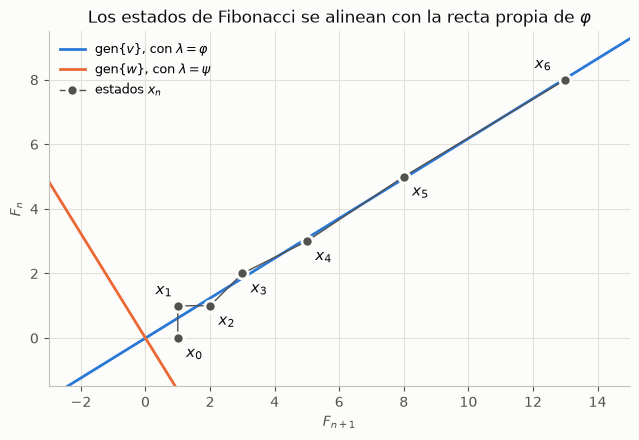

In [8]:
xs = [(fib_exacto(j + 1), fib_exacto(j)) for j in range(7)]

fig, ax = plt.subplots(figsize=(7.5, 5.6))
t = np.array([-20, 20])
ax.plot(t * phi_f, t, color=AZUL, lw=2, label=r"$\mathrm{gen}\{v\}$, con $\lambda=\varphi$")
ax.plot(t * psi_f, t, color=NARANJA, lw=2, label=r"$\mathrm{gen}\{w\}$, con $\lambda=\psi$")
ax.plot(*zip(*xs), "o-", color=TINTA_SUAVE, lw=1, markersize=8, markeredgecolor="#fcfcfb",
        markeredgewidth=2, label="estados $x_n$")

desplazamientos = {0: (6, -14), 1: (-16, 8), 2: (6, -14), 3: (6, -14), 4: (6, -14), 5: (6, -14), 6: (-22, 8)}
for j, punto in enumerate(xs):
    ax.annotate(f"$x_{j}$", punto, textcoords="offset points", xytext=desplazamientos[j],
                color=TINTA, fontsize=11)

ax.set_aspect("equal")
ax.set_xlim(-3, 15)
ax.set_ylim(-1.5, 9.5)
ax.set_xlabel("$F_{n+1}$")
ax.set_ylabel("$F_n$")
ax.set_title("Los estados de Fibonacci se alinean con la recta propia de $\\varphi$")
ax.legend(loc="upper left", fontsize=9)
plt.show()

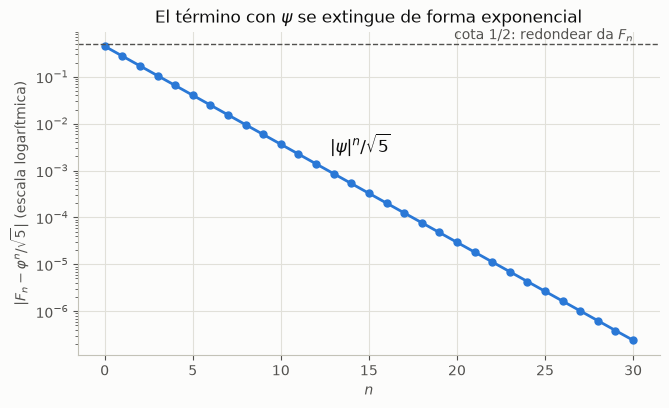

In [9]:
ns = np.arange(0, 31)
error = np.array([abs(fib_exacto(int(j)) - phi_f ** int(j) / 5**0.5) for j in ns])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(ns, error, color=AZUL, lw=2, marker="o", markersize=5)
ax.axhline(0.5, color=TINTA_SUAVE, lw=1, linestyle="--")
ax.text(30, 0.62, "cota 1/2: redondear da $F_n$", ha="right", color=TINTA_SUAVE, fontsize=10)
ax.annotate(r"$|\psi|^n/\sqrt{5}$", (12, error[12]), textcoords="offset points", xytext=(10, 8),
            color=TINTA, fontsize=12)
ax.set_xlabel("$n$")
ax.set_ylabel(r"$|F_n-\varphi^n/\sqrt{5}|$ (escala logarítmica)")
ax.set_title("El término con $\\psi$ se extingue de forma exponencial")
plt.show()

## 5. Resumen

- $\lambda$ es **valor propio** de $A$ con **vector propio** $v\ne\mathbf 0$ si $Av=\lambda v$: en la dirección de $v$, la matriz solo escala.
- Los valores propios son las raíces de $\det(A-\lambda I)=0$; los vectores propios se obtienen de $E_\lambda=\operatorname{Nul}(A-\lambda I)$.
- $A$ es **diagonalizable**, $A=PDP^{-1}$, $\iff$ tiene $n$ vectores propios independientes. Las columnas de $P$ son los vectores propios y $D$ contiene los valores propios en el mismo orden.
- $n$ valores propios distintos garantizan la diagonalización. En general se necesitan raíces reales y $m_g(\lambda)=m_a(\lambda)$ para cada $\lambda$.
- $D$ es la misma transformación vista en la base de vectores propios, y $A^k=PD^kP^{-1}$.
- **Fibonacci:** $A=\begin{pmatrix}1&1\\1&0\end{pmatrix}$ tiene $\lambda^2-\lambda-1=0$, con raíces $\varphi,\psi$ y vectores propios $(\varphi,1)$, $(\psi,1)$. Al diagonalizar se obtiene
$$F_n=\frac{\varphi^n-\psi^n}{\sqrt5},$$
y como $|\psi|<1$, se concluye que $F_n$ es el entero más cercano a $\varphi^n/\sqrt5$ y que $F_{n+1}/F_n\to\varphi$.

## 6. Ejercicios

### A. Cálculo de valores y vectores propios

1. Halle los valores propios y una base de cada espacio propio. Diagonalice cuando sea posible, indicando $P$ y $D$, y compruebe con $AP=PD$:
   - (a) $\begin{pmatrix}3&1\\1&3\end{pmatrix}$
   - (b) $\begin{pmatrix}5&-1\\1&3\end{pmatrix}$
   - (c) $\begin{pmatrix}2&0&0\\0&3&4\\0&4&9\end{pmatrix}$
   - (d) $\begin{pmatrix}1&1&1\\1&1&1\\1&1&1\end{pmatrix}$
2. Sin hacer cálculos, dé los valores propios y los vectores propios de la reflexión sobre la recta $y=x$ en $\mathbb{R}^2$. Escriba su matriz y confirme la respuesta.
3. Encuentre los valores propios de $\begin{pmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{pmatrix}$. ¿Para qué valores de $\theta$ son reales? Interprete geométricamente.

### B. Demostraciones

4. Demuestre que $A$ es invertible si y solo si $0$ no es valor propio de $A$.
5. Si $Av=\lambda v$ y $A$ es invertible, demuestre que $A^{-1}v=\lambda^{-1}v$.
6. Demuestre que $A$ y $A^T$ tienen el mismo polinomio característico. ¿Tienen también los mismos vectores propios? Dé un ejemplo.
7. Si $B=Q^{-1}AQ$, demuestre que $A$ y $B$ tienen el mismo polinomio característico. ¿Qué relación hay entre sus vectores propios?

### C. Potencias y diagonalización

8. Diagonalice $A=\begin{pmatrix}1&2\\0&3\end{pmatrix}$ y obtenga una fórmula para $A^k$. Úsela para calcular $A^5$.
9. **Cadena de Markov.** Cada mes, $90\%$ de los clientes de la plataforma X se queda y $10\%$ pasa a Y, mientras que $80\%$ de los de Y se queda y $20\%$ pasa a X. Esto se describe con $M=\begin{pmatrix}0.9&0.2\\0.1&0.8\end{pmatrix}$. Diagonalice $M$, calcule $\lim_{k\to\infty}M^k$ y halle la proporción de clientes a largo plazo. ¿Depende de la distribución inicial?

### D. Fibonacci y otras recurrencias

10. Con $A$ y su diagonalización de la sección 4, y $(L_1,L_0)=(1,2)$, demuestre que los números de Lucas (Cuaderno13, ejercicio 3) cumplen $L_n=\varphi^n+\psi^n$. Calcule $L_{10}$ con la fórmula.
11. Demuestre por inducción que $\varphi^n=F_n\varphi+F_{n-1}$ para $n\ge1$.
12. Deduzca la identidad de Cassini, $F_{n+1}F_{n-1}-F_n^2=(-1)^n$, a partir de la fórmula de Binet.
13. Use la sección 4.2 para calcular cuántas cifras tiene $F_{1000}$, y compruebe el resultado en Python.
14. Halle una fórmula cerrada, siguiendo los pasos de la sección 4, para:
    - (a) $a_0=0,\ a_1=1,\ a_{n+1}=a_n+2a_{n-1}$;
    - (b) los números de Pell: $p_0=0,\ p_1=1,\ p_{n+1}=2p_n+p_{n-1}$.
15. Con la matriz de **Tribonacci** del ejercicio 4 del Cuaderno13, calcule en NumPy sus valores propios. ¿Cuál determina el crecimiento de la sucesión? Compare ese valor con $T_{n+1}/T_n$ para $n$ grande.

# Un ejercicio difícil 

In [54]:
import sympy as sp

lam = sp.symbols("lambda")
A = sp.Matrix([[-1,  2, 2],
               [ 2, -1, 2],
               [ 2,  2, 1]])
A

⎡-1  2   2⎤
⎢         ⎥
⎢2   -1  2⎥
⎢         ⎥
⎣2   2   1⎦

In [56]:
p = (A - lam*sp.eye(3)).det()
p

   3    2            
- λ  - λ  + 13⋅λ + 21

In [57]:
sp.factor(p)

         ⎛ 2          ⎞
-(λ + 3)⋅⎝λ  - 2⋅λ - 7⎠

In [58]:
a = sp.solve(lam**2 - 2*lam - 7, lam)
a

[1 - 2⋅√2, 1 + 2⋅√2]

## Veamos la reducción paso a paso

In [67]:
B = (A - a[0]*sp.eye(3))
B

⎡-2 + 2⋅√2      2       2  ⎤
⎢                          ⎥
⎢    2      -2 + 2⋅√2   2  ⎥
⎢                          ⎥
⎣    2          2      2⋅√2⎦

In [72]:
A = B.rref()[0]#.simplify()
A

⎡      4 - 3⋅√2 ⎤
⎢1  0  ─────────⎥
⎢      -6 + 4⋅√2⎥
⎢               ⎥
⎢       2 - √2  ⎥
⎢0  1  ─────────⎥
⎢      -2 + 2⋅√2⎥
⎢               ⎥
⎣0  0      0    ⎦

In [73]:
A.simplify()
A

⎡      √2⎤
⎢1  0  ──⎥
⎢      2 ⎥
⎢        ⎥
⎢      √2⎥
⎢0  1  ──⎥
⎢      2 ⎥
⎢        ⎥
⎣0  0  0 ⎦

In [60]:
B[0,:] = B[0,:]/B[0,0]
B[1,:] = B[1,:] - B[1,0]*B[0,:]
B[2,:] = B[2,:] - B[2,0]*B[0,:]
B

⎡             2                     2         ⎤
⎢1        ─────────             ─────────     ⎥
⎢         -2 + 2⋅√2             -2 + 2⋅√2     ⎥
⎢                                             ⎥
⎢         4                           4       ⎥
⎢0  - ───────── - 2 + 2⋅√2    2 - ─────────   ⎥
⎢     -2 + 2⋅√2                   -2 + 2⋅√2   ⎥
⎢                                             ⎥
⎢               4                 4           ⎥
⎢0      2 - ─────────       - ───────── + 2⋅√2⎥
⎣           -2 + 2⋅√2         -2 + 2⋅√2       ⎦

In [61]:
B.simplify()
B

⎡1  1 + √2  1 + √2⎤
⎢                 ⎥
⎢0    -4    -2⋅√2 ⎥
⎢                 ⎥
⎣0  -2⋅√2     -2  ⎦

In [64]:
B[1,:] = B[1,:]/B[1,1]
B[0,:] = B[0,:] - B[0,1]*B[1,:]
B[2,:] = B[2,:] - B[2,1]*B[1,:]
B

⎡        √2⋅(1 + √2)         ⎤
⎢1  0  - ─────────── + 1 + √2⎥
⎢             2              ⎥
⎢                            ⎥
⎢                √2          ⎥
⎢0  1            ──          ⎥
⎢                2           ⎥
⎢                            ⎥
⎣0  0            0           ⎦

In [65]:
B.simplify()

In [66]:
B

⎡      √2⎤
⎢1  0  ──⎥
⎢      2 ⎥
⎢        ⎥
⎢      √2⎥
⎢0  1  ──⎥
⎢      2 ⎥
⎢        ⎥
⎣0  0  0 ⎦